In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split

In [3]:
# Load Dataset
df = pd.read_csv("advertising.csv")

# Statistical summary
print("Statistical summary:")
pd.set_option("display.float_format", lambda x: "%.6f" % x)
print(df.describe())
print("\n" + "=" * 50 + "\n")

# Features and Target Variable
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

Statistical summary:
              TV      Radio  Newspaper      Sales
count 200.000000 200.000000 200.000000 200.000000
mean  147.042500  23.264000  30.554000  15.127500
std    85.854236  14.846809  21.778621   5.214966
min     0.700000   0.000000   0.300000   5.300000
25%    74.375000   9.975000  12.750000  10.900000
50%   149.750000  22.900000  25.750000  15.700000
75%   218.825000  36.525000  45.100000  18.900000
max   296.400000  49.600000 114.000000  26.200000




In [5]:
# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Train Multiple Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Continuous Predictions on Test Data
y_pred = model.predict(X_test)

In [6]:
# Regression Evaluation Metrics (MAE, MSE, RMSE, R2)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Classification Evaluation Metrics (Accuracy, F1 Score)
# Business Benchmark Threshold: Sales >= 15 units = High Performance (1), else Low (0)
threshold = 15.0
y_test_class = (np.array(y_test) >= threshold).astype(int)
y_pred_class = (y_pred >= threshold).astype(int)

accuracy = accuracy_score(y_test_class, y_pred_class)
f1 = f1_score(y_test_class, y_pred_class)

In [7]:
print("Actual Sales:")
print(np.array(y_test))
print("\nPredicted Sales:")
print(np.array2string(y_pred, separator=" ", max_line_width=80))
print("\n" + "=" * 50 + "\n")

print("Model Evaluation Metrics:")
print("-------------------------")
print(f"MAE       : {mae:.6f}")
print(f"MSE       : {mse:.6f}")
print(f"RMSE      : {rmse:.6f}")
print(f"R2 Score  : {r2:.6f}")
print(f"Accuracy  : {accuracy * 100:.2f}% (Threshold >= {threshold})")
print(f"F1 Score  : {f1:.4f}")
print("\n" + "=" * 50 + "\n")

# Model Coefficients
print("Model Coefficients")
print("------------------")
print(f"Intercept : {model.intercept_}")
for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature:<9}: {coef}")
print("\n" + "=" * 50 + "\n")

Actual Sales:
[16.9 22.4 21.4  7.3 24.7 12.6 22.3  8.4 16.5 16.1 11.   8.7 16.9  5.3
 10.3 16.7  5.5 16.6 11.3 18.9 19.7 12.5 10.9 22.2 11.3  8.1 21.7 13.4
 10.6  5.7 15.6 11.3 23.7  8.7 16.1 20.7 11.6 20.8 11.9  6.9]

Predicted Sales:
[17.02615865 20.40182379 23.71323243  9.27128627 21.68578728 12.5639594
 21.07821795  8.69124419 17.23287408 16.66163509  8.93060441  8.4791657
 18.18621921  8.07384117 12.64067405 14.92442098  8.12674292 17.89725287
 11.0065286  20.47676049 20.79072001 12.57944683 10.91101029 22.37316736
  9.42211008  7.92413372 20.83457245 13.815529   10.76880322  7.93448719
 15.95406383 10.63616543 20.79341255 10.42305796 21.5680283  21.1841055
 12.13522662 22.79558129 12.61208429  6.46441541]


Model Evaluation Metrics:
-------------------------
MAE       : 1.272448
MSE       : 2.900942
RMSE      : 1.703215
R2 Score  : 0.906122
Accuracy  : 97.50% (Threshold >= 15.0)
F1 Score  : 0.9730


Model Coefficients
------------------
Intercept : 4.7196651741389
TV       : 0.05

In [8]:
# Scenario Simulation: Test a New Planned Budget
new_budget = pd.DataFrame({"TV": [150], "Radio": [20], "Newspaper": [30]})
prediction = model.predict(new_budget)

print("New Advertising Budget:")
print(new_budget)
print("\nPredicted Sales:")
print(prediction[0])

New Advertising Budget:
    TV  Radio  Newspaper
0  150     20         30

Predicted Sales:
15.035457300581992


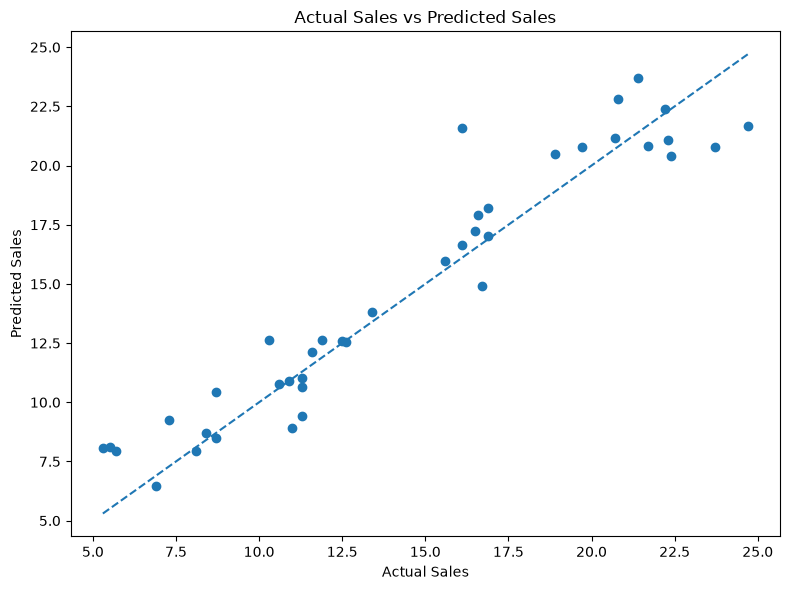

In [9]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color="#1f77b4")
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "--", color="#1f77b4")
plt.title("Actual Sales vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.tight_layout()
plt.show()